# METABRIC Ward clustering negative control with 20 PCs

This notebook reproduces the observed analysis in [Tirzah's Ward notebook](./Ward%20Clustering%20and%20comparison%20to%20PAM50.ipynb). It then independently shuffles each gene across patients and refits median imputation, standardization, 20-component PCA, and Ward clustering in every replicate. The comparison tests how much cluster separation and PAM50 agreement exceed the values obtained when each gene keeps its observed distribution and the cross-gene structure is disrupted.

Ward is fitted on all 1,980 expression samples. Silhouette uses that full cohort. Adjusted Rand index (ARI) and normalized mutual information (NMI) use the 1,756 samples in the five standard PAM50 classes. The two headline cuts are **k = 2** and **k = 5**, with **k = 2–10** reported below.

To rerun, use a Python kernel with NumPy, pandas, SciPy, scikit-learn, and Matplotlib. Set the `METABRIC_DATA_DIR` environment variable or edit the data path in the next cell if your local directory differs.

In [1]:
import os
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler

get_ipython().run_line_magic("matplotlib", "inline")

DATA_DIR = Path(os.environ.get("METABRIC_DATA_DIR", "~/Documents/brca/brca_metabric")).expanduser()
EXPRESSION_FILE = "data_mrna_illumina_microarray.txt"
PATIENT_FILE = "data_clinical_patient.txt"
SAMPLE_FILE = "data_clinical_sample.txt"
MAIN_SUBTYPES = ["LumA", "LumB", "Her2", "Basal", "Normal"]
N_PCS = 20
K_VALUES = range(2, 11)
N_SHUFFLES = 100
SEED = 707

for filename in (EXPRESSION_FILE, PATIENT_FILE, SAMPLE_FILE):
    if not (DATA_DIR / filename).is_file():
        raise FileNotFoundError(f"Missing {filename} in {DATA_DIR}. Set METABRIC_DATA_DIR to the study folder.")
if N_SHUFFLES < 1:
    raise ValueError("N_SHUFFLES must be at least 1.")

print(f"Data directory: {DATA_DIR}")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__}")

Data directory: /Users/danielbility/Documents/brca/brca_metabric
NumPy 2.3.5 | pandas 2.2.3 | SciPy 1.18.1 | scikit-learn 1.9.1


## Reproduce Tirzah's gene selection

Read the same microarray expression file, average rows by numeric Entrez ID, and transpose to one row per sample. Retain genes with at most 10% missing observations and positive median absolute deviation (MAD). Take the 2,000 largest MAD values before imputation or scaling.

In [2]:
raw_expression = pd.read_csv(DATA_DIR / EXPRESSION_FILE, sep="	", low_memory=False)
entrez_id = pd.to_numeric(raw_expression["Entrez_Gene_Id"], errors="coerce")
has_entrez_id = entrez_id.notna()
expression = raw_expression.loc[has_entrez_id].drop(columns=["Hugo_Symbol", "Entrez_Gene_Id"])
expression.index = pd.Index(entrez_id.loc[has_entrez_id].astype(int), name="Entrez_Gene_Id")
expression = expression.apply(pd.to_numeric, errors="coerce").groupby(level=0).mean().T
del raw_expression

eligible = expression.loc[:, expression.isna().mean().le(0.10)]
gene_mad = eligible.sub(eligible.median(axis=0), axis=1).abs().median(axis=0)
top_mad = gene_mad[gene_mad.gt(0)].nlargest(2000)
X_2000 = eligible.loc[:, top_mad.index].copy()
del eligible, expression

assert X_2000.shape == (1980, 2000), f"Unexpected expression shape: {X_2000.shape}"
assert X_2000.index.is_unique
assert top_mad.index[:10].tolist() == [4250, 7031, 5304, 10647, 118430, 10451, 4680, 6286, 9, 149563]
assert X_2000.isna().to_numpy().sum() == 6
print(f"Selected {X_2000.shape[1]:,} genes across {X_2000.shape[0]:,} samples")
print(f"Missing expression entries before imputation: {X_2000.isna().to_numpy().sum()}")
display(top_mad.head(10).rename("MAD").to_frame().round(6))

Selected 2,000 genes across 1,980 samples
Missing expression entries before imputation: 6


,MAD
Entrez_Gene_Id,
4250,2.654036
7031,2.434716
5304,2.401594
10647,2.316080
118430,2.254858
10451,2.147834
4680,1.964515
6286,1.948658
9,1.792440


## Align PAM50 labels by sample ID

Join sample IDs to patient-level `CLAUDIN_SUBTYPE` and align to the expression rows. The subtype mask is used only for ARI and NMI after clustering.

In [3]:
clinical_patients = pd.read_csv(
    DATA_DIR / PATIENT_FILE, sep="	", comment="#", usecols=["PATIENT_ID", "CLAUDIN_SUBTYPE"]
)
clinical_samples = pd.read_csv(
    DATA_DIR / SAMPLE_FILE, sep="	", comment="#", usecols=["SAMPLE_ID", "PATIENT_ID"]
)
assert clinical_samples["SAMPLE_ID"].is_unique
assert clinical_patients["PATIENT_ID"].is_unique

pam50 = (
    clinical_samples.merge(clinical_patients, on="PATIENT_ID", how="left", validate="many_to_one")
    .set_index("SAMPLE_ID")["CLAUDIN_SUBTYPE"]
    .reindex(X_2000.index)
)
assert pam50.index.equals(X_2000.index)
assert pam50.notna().all()
main_mask = pam50.isin(MAIN_SUBTYPES).to_numpy()
assert main_mask.sum() == 1756
print(f"{main_mask.sum():,} samples used for PAM50 agreement out of {len(pam50):,} fitted samples")
display(pam50.value_counts().rename("Samples").to_frame())

1,756 samples used for PAM50 agreement out of 1,980 fitted samples


,Samples
CLAUDIN_SUBTYPE,
LumA,700
LumB,475
Her2,224
claudin-low,218
Basal,209
Normal,148
NC,6


## Fit and score the observed Ward solution

Median-impute and standardize each gene, then fit PCA with Tirzah's full SVD solver. Calculate Euclidean distances in the first 20 unwhitened PCs and cut the resulting Ward linkage tree at each requested k. Reuse the distance matrix for all silhouette scores. NMI uses arithmetic averaging. Cluster IDs can be permuted without affecting ARI, NMI, or silhouette.

In [4]:
METRICS = ["silhouette", "ari", "nmi"]


def fit_and_score_ward(expression_values, subtype_labels, subtype_mask, k_values):
    imputed = SimpleImputer(strategy="median").fit_transform(expression_values)
    scaled = StandardScaler().fit_transform(imputed)
    pca = PCA(n_components=N_PCS, svd_solver="full")
    pcs = pca.fit_transform(scaled)
    condensed_distances = pdist(pcs, metric="euclidean")
    tree = linkage(condensed_distances, method="ward")
    distances = squareform(condensed_distances)

    assignments = {}
    scores = []
    for k in k_values:
        clusters = fcluster(tree, t=k, criterion="maxclust")
        actual_k = np.unique(clusters).size
        if actual_k != k:
            raise ValueError(f"Ward returned {actual_k} clusters for k={k}.")
        assignments[k] = clusters
        subset = clusters[subtype_mask]
        scores.append({
            "k": k,
            "silhouette": silhouette_score(distances, clusters, metric="precomputed"),
            "ari": adjusted_rand_score(subtype_labels, subset),
            "nmi": normalized_mutual_info_score(subtype_labels, subset, average_method="arithmetic"),
        })
    return pd.DataFrame(scores).set_index("k"), assignments, pca.explained_variance_ratio_.sum()


X = X_2000.to_numpy(dtype=float)
y = pam50.to_numpy()[main_mask]
observed, observed_clusters, observed_variance = fit_and_score_ward(X, y, main_mask, K_VALUES)

# Check the observed run against the silhouettes and clustered sample counts in Tirzah's notebook.
reference_silhouettes = [0.166, 0.108, 0.105, 0.105, 0.108, 0.096, 0.079, 0.075, 0.079]
np.testing.assert_allclose(observed["silhouette"], reference_silhouettes, atol=0.0005, rtol=0)
np.testing.assert_array_equal(
    np.bincount(observed_clusters[5])[1:], [205, 363, 694, 174, 544]
)

np.testing.assert_allclose(observed_variance, 0.5841, atol=0.00005, rtol=0)
print(f"Variance explained by the first {N_PCS} PCs: {observed_variance:.2%}")
print("Observed Ward silhouettes and k=5 cluster sizes reproduce Tirzah's PCA results.")
display(observed.round(4))

Variance explained by the first 20 PCs: 58.41%
Observed Ward silhouettes and k=5 cluster sizes reproduce Tirzah's PCA results.


,silhouette,ari,nmi
k,,,
2,0.1663,0.2183,0.2475
3,0.1075,0.2047,0.2394
4,0.1050,0.2161,0.2405
5,0.1053,0.2353,0.2878
6,0.1078,0.2356,0.2877
7,0.0964,0.2190,0.2831
8,0.0791,0.1943,0.2804
9,0.0751,0.1905,0.2855
10,0.0786,0.1940,0.2951


## Generate the shuffled controls

Independently permute the observed values of each gene across its nonmissing rows. This preserves the missingness mask, each gene's distribution, and its MAD. The same genes would therefore pass a rerun of the selection step. Leave the sample order and subtype labels fixed, and refit imputation, scaling, PCA, and Ward for every replicate.

The loop uses reproducible random streams indexed by the seed and replicate number. It retains one set of scores per replicate and k.

In [5]:
def shuffle_expression(values, rng):
    shuffled = np.empty_like(values)
    for feature in range(values.shape[1]):
        column = values[:, feature]
        observed_rows = ~np.isnan(column)
        if observed_rows.all():
            shuffled[:, feature] = rng.permutation(column)
        else:
            shuffled[:, feature] = np.nan
            shuffled[observed_rows, feature] = rng.permutation(column[observed_rows])
    return shuffled


started = perf_counter()
null_runs = []
shuffled_variances = []
for replicate in range(1, N_SHUFFLES + 1):
    rng = np.random.default_rng(np.random.SeedSequence([SEED, replicate]))
    shuffled = shuffle_expression(X, rng)
    if replicate == 1:
        np.testing.assert_array_equal(np.isnan(shuffled), np.isnan(X))
        np.testing.assert_array_equal(np.sort(shuffled, axis=0), np.sort(X, axis=0))
        if np.array_equal(shuffled, X, equal_nan=True):
            raise ValueError("The first shuffle did not change any expression values.")
        print("First shuffle preserves every gene's values and missingness positions.", flush=True)

    scores, _, variance = fit_and_score_ward(shuffled, y, main_mask, K_VALUES)
    shuffled_variances.append(variance)
    null_runs.append(scores.assign(replicate=replicate))
    if replicate == 1 or replicate % 10 == 0 or replicate == N_SHUFFLES:
        print(f"Completed {replicate}/{N_SHUFFLES} shuffles in {perf_counter() - started:.1f} s.", flush=True)

null_scores = pd.concat(null_runs).reset_index().set_index(["replicate", "k"]).sort_index()
assert len(null_scores) == N_SHUFFLES * len(K_VALUES)
assert null_scores.index.is_unique
assert np.isfinite(null_scores[METRICS].to_numpy()).all()
print(f"The first {N_PCS} PCs explain a median {np.median(shuffled_variances):.2%} of shuffled variance.")

First shuffle preserves every gene's values and missingness positions.
Completed 1/100 shuffles in 1.3 s.
Completed 10/100 shuffles in 11.8 s.
Completed 20/100 shuffles in 23.3 s.
Completed 30/100 shuffles in 34.4 s.
Completed 40/100 shuffles in 46.2 s.
Completed 50/100 shuffles in 57.5 s.
Completed 60/100 shuffles in 69.1 s.
Completed 70/100 shuffles in 80.6 s.
Completed 80/100 shuffles in 92.0 s.
Completed 90/100 shuffles in 103.9 s.
Completed 100/100 shuffles in 115.5 s.
The first 20 PCs explain a median 3.82% of shuffled variance.


## Compare observed and shuffled scores

Each faint orange line tracks one shuffled replicate across k. The dashed line and shaded band show the shuffled median and central 95% at each k. The one-sided empirical p-value is `(1 + number of shuffled scores at least as large as observed) / (1 + number of shuffles)`. These are pointwise results for each k and metric. The analysis does not adjust for scanning across k or metrics.

In [6]:
summary_rows = []
for k in K_VALUES:
    null_at_k = null_scores.xs(k, level="k")
    for metric in METRICS:
        real_score = observed.loc[k, metric]
        null_values = null_at_k[metric]
        low, median, high = null_values.quantile([0.025, 0.5, 0.975])
        n_ge_observed = int(null_values.ge(real_score).sum())
        summary_rows.append({
            "k": k,
            "metric": metric,
            "observed": real_score,
            "null_median": median,
            "null_2.5%": low,
            "null_97.5%": high,
            "shuffles_at_least_observed": n_ge_observed,
            "empirical_p": (1 + n_ge_observed) / (1 + len(null_values)),
        })

summary = pd.DataFrame(summary_rows).set_index(["k", "metric"])
print("Headline cuts")
display(summary.loc[[2, 5]].round(4))
print("All Ward cuts")
display(summary.round(4))

Headline cuts


observed  null_median  ...  shuffles_at_least_observed  empirical_p
k metric                             ...                                         
2 silhouette    0.1663       0.0138  ...                           0       0.0099
  ari           0.2183      -0.0004  ...                           0       0.0099
  nmi           0.2475       0.0009  ...                           0       0.0099
5 silhouette    0.1053       0.0027  ...                           0       0.0099
  ari           0.2353      -0.0002  ...                           0       0.0099
  nmi           0.2878       0.0028  ...                           0       0.0099

[6 rows x 6 columns]

All Ward cuts


observed  null_median  ...  shuffles_at_least_observed  empirical_p
k  metric                             ...                                         
2  silhouette    0.1663       0.0138  ...                           0       0.0099
   ari           0.2183      -0.0004  ...                           0       0.0099
   nmi           0.2475       0.0009  ...                           0       0.0099
3  silhouette    0.1075       0.0078  ...                           0       0.0099
   ari           0.2047      -0.0002  ...                           0       0.0099
   nmi           0.2394       0.0015  ...                           0       0.0099
4  silhouette    0.1050       0.0047  ...                           0       0.0099
   ari           0.2161       0.0003  ...                           0       0.0099
   nmi           0.2405       0.0023  ...                           0       0.0099
5  silhouette    0.1053       0.0027  ...                           0       0.0099
   ari           0.2353      -0.0002  ...                           0       0.0099
   nmi           0.2878       0.0028  ...                           0       0.0099
6  silhouette    0.1078       0.0015  ...                           0       0.0099
   ari           0.2356      -0.0007  ...                           0       0.0099
   nmi           0.2877       0.0033  ...                           0       0.0099
7  silhouette    0.0964       0.0008  ...                           0       0.0099
   ari           0.2190      -0.0010  ...                           0       0.0099
   nmi           0.2831       0.0038  ...                           0       0.0099
8  silhouette    0.0791       0.0002  ...                           0       0.0099
   ari           0.1943      -0.0002  ...                           0       0.0099
   nmi           0.2804       0.0043  ...                           0       0.0099
9  silhouette    0.0751      -0.0003  ...                           0       0.0099
   ari           0.1905      -0.0000  ...                           0       0.0099
   nmi           0.2855       0.0050  ...                           0       0.0099
10 silhouette    0.0786      -0.0006  ...                           0       0.0099
   ari           0.1940      -0.0001  ...                           0       0.0099
   nmi           0.2951       0.0055  ...                           0       0.0099

[27 rows x 6 columns]

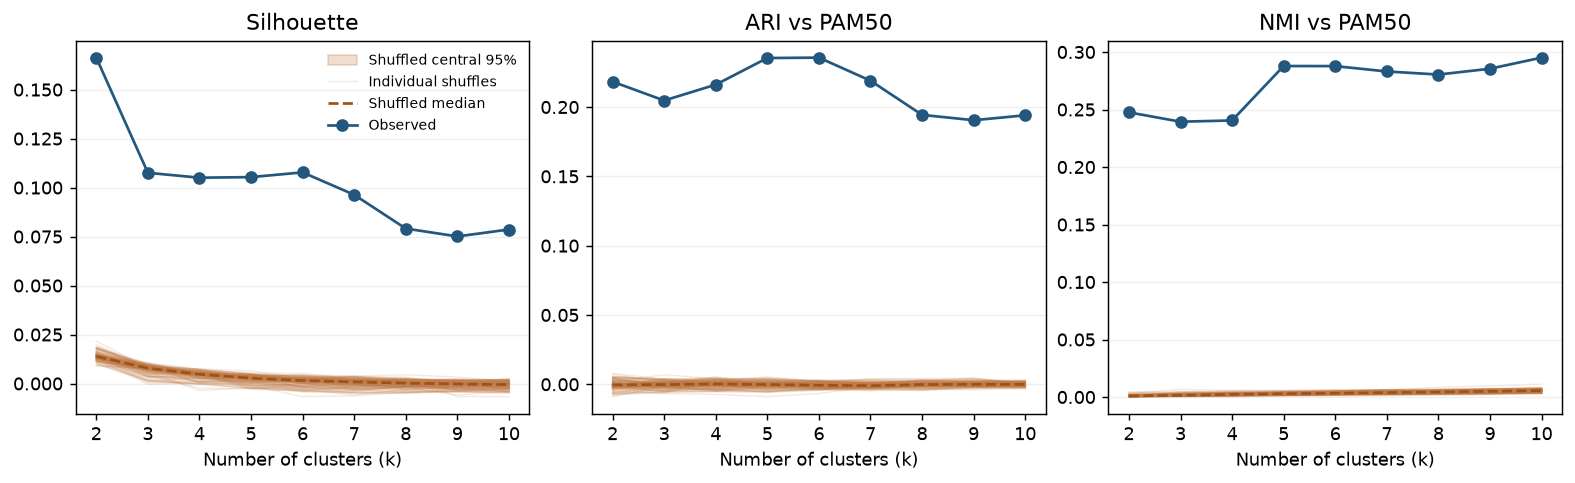

In [7]:
metric_titles = {"silhouette": "Silhouette", "ari": "ARI vs PAM50", "nmi": "NMI vs PAM50"}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")

for ax, metric in zip(axes, METRICS):
    rows = summary.xs(metric, level="metric")
    k = rows.index.to_numpy()
    shuffled = null_scores[metric].unstack("replicate").reindex(k)
    ax.fill_between(
        k, rows["null_2.5%"], rows["null_97.5%"], alpha=0.22, color="#b76b25",
        label="Shuffled central 95%",
    )
    shuffled_lines = ax.plot(k, shuffled, color="#bf7a47", alpha=0.16, linewidth=0.8)
    shuffled_lines[0].set_label("Individual shuffles")
    ax.plot(
        k, rows["null_median"], linestyle="--", color="#9d5318",
        label="Shuffled median", zorder=3,
    )
    ax.plot(k, rows["observed"], marker="o", color="#23577e", label="Observed")
    ax.set(title=metric_titles[metric], xlabel="Number of clusters (k)", xticks=k)
    ax.grid(axis="y", alpha=0.2)

axes[0].legend(frameon=False, fontsize=8)
plt.show()

In [8]:
for k in (2, 5):
    above_interval = [
        metric_titles[metric] for metric in METRICS
        if summary.loc[(k, metric), "observed"] > summary.loc[(k, metric), "null_97.5%"]
    ]
    labels = ", ".join(above_interval) if above_interval else "none"
    print(f"k = {k} | Observed scores above the shuffled 97.5th percentile: {labels}")

print(
    "This comparison assesses cluster separation and PAM50 agreement against the gene-wise shuffle. "
    "Cohort effects and overlap with the PAM50 gene panel are separate sensitivity questions."
)

k = 2 | Observed scores above the shuffled 97.5th percentile: Silhouette, ARI vs PAM50, NMI vs PAM50
k = 5 | Observed scores above the shuffled 97.5th percentile: Silhouette, ARI vs PAM50, NMI vs PAM50
This comparison assesses cluster separation and PAM50 agreement against the gene-wise shuffle. Cohort effects and overlap with the PAM50 gene panel are separate sensitivity questions.
